In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import warnings

warnings.filterwarnings("ignore")

In [4]:
# Rutas del proyecto
DATA_RAW       = Path("../data/raw/creditcard.csv")
DATA_PROCESSED = Path("../data/processed/")
FIG_DIR        = Path("../reports/figures/")

# Crear carpetas si no existen
FIG_DIR.mkdir(parents=True, exist_ok=True)
DATA_PROCESSED.mkdir(parents=True, exist_ok=True)

# Estilos
plt.rcParams.update({
    "figure.facecolor":  "white",
    "axes.facecolor":    "#F8F8F8",
    "axes.grid":         True,
    "grid.color":        "white",
    "axes.spines.top":   False,
    "axes.spines.right": False,
    "font.size":         11,
    "figure.dpi":        120,
})

# Colores del proyecto
C_LEGIT = "#2196F3"   # azul — transacción legítima
C_FRAUD = "#E53935"   # rojo  — fraude

print("Configuración lista ✓")

Configuración lista ✓


In [5]:
df = pd.read_csv(DATA_RAW)

print(f"Dimensiones: {df.shape[0]:,} filas × {df.shape[1]} columnas")
print(f"\nColumnas: {df.columns.tolist()}")

Dimensiones: 284,807 filas × 31 columnas

Columnas: ['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount', 'Class']


In [6]:
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [7]:
print("Tipos de datos:")
print(df.dtypes)
print(f"\nValores nulos:")
print(df.isnull().sum())
print(f"\nTotal nulos: {df.isnull().sum().sum()}")

Tipos de datos:
Time      float64
V1        float64
V2        float64
V3        float64
V4        float64
V5        float64
V6        float64
V7        float64
V8        float64
V9        float64
V10       float64
V11       float64
V12       float64
V13       float64
V14       float64
V15       float64
V16       float64
V17       float64
V18       float64
V19       float64
V20       float64
V21       float64
V22       float64
V23       float64
V24       float64
V25       float64
V26       float64
V27       float64
V28       float64
Amount    float64
Class       int64
dtype: object

Valores nulos:
Time      0
V1        0
V2        0
V3        0
V4        0
V5        0
V6        0
V7        0
V8        0
V9        0
V10       0
V11       0
V12       0
V13       0
V14       0
V15       0
V16       0
V17       0
V18       0
V19       0
V20       0
V21       0
V22       0
V23       0
V24       0
V25       0
V26       0
V27       0
V28       0
Amount    0
Class     0
dtype: int64

Total nulo

In [8]:
conteo = df["Class"].value_counts()
porcentaje = df["Class"].value_counts(normalize=True) * 100

print("Distribución del target:")
print(f"  Legítimas (0): {conteo[0]:,} ({porcentaje[0]:.3f}%)")
print(f"  Fraudes   (1): {conteo[1]:,} ({porcentaje[1]:.3f}%)")
print(f"\nRatio desbalanceo: 1:{int(conteo[0]/conteo[1])}")

Distribución del target:
  Legítimas (0): 284,315 (99.827%)
  Fraudes   (1): 492 (0.173%)

Ratio desbalanceo: 1:577


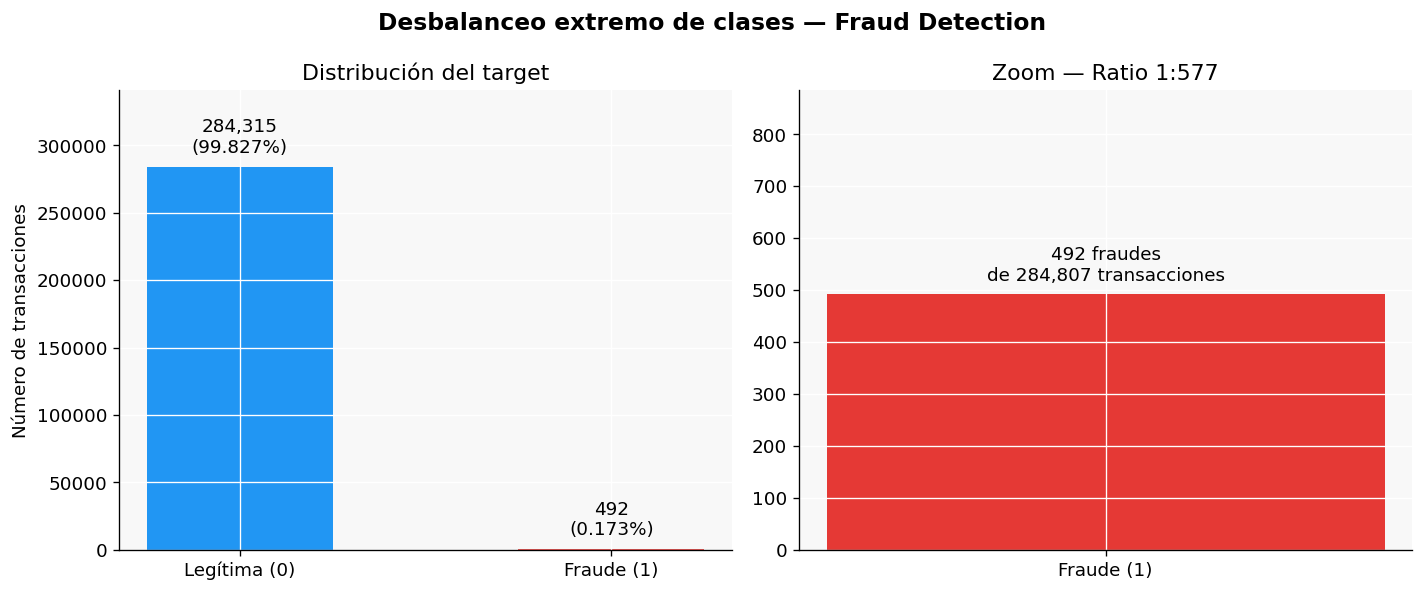

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Barras
ax = axes[0]
bars = ax.bar(
    ["Legítima (0)", "Fraude (1)"],
    conteo.values,
    color=[C_LEGIT, C_FRAUD],
    width=0.5
)
ax.bar_label(bars,
    labels=[f"{v:,}\n({p:.3f}%)"
            for v, p in zip(conteo.values, porcentaje.values)],
    padding=6
)
ax.set_ylabel("Número de transacciones")
ax.set_title("Distribución del target")
ax.set_ylim(0, conteo.max() * 1.2)

# Zoom en fraudes
ax = axes[1]
ax.bar(["Fraude (1)"], [conteo[1]],
       color=C_FRAUD, width=0.3)
ax.bar_label(ax.containers[0],
             labels=[f"{conteo[1]:,} fraudes\nde {len(df):,} transacciones"],
             padding=6)
ax.set_title(f"Zoom — Ratio 1:{int(conteo[0]/conteo[1])}")
ax.set_ylim(0, conteo[1] * 1.8)

plt.suptitle("Desbalanceo extremo de clases — Fraud Detection",
             fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig(FIG_DIR / "01_desbalanceo_clases.png", bbox_inches="tight")
plt.show()

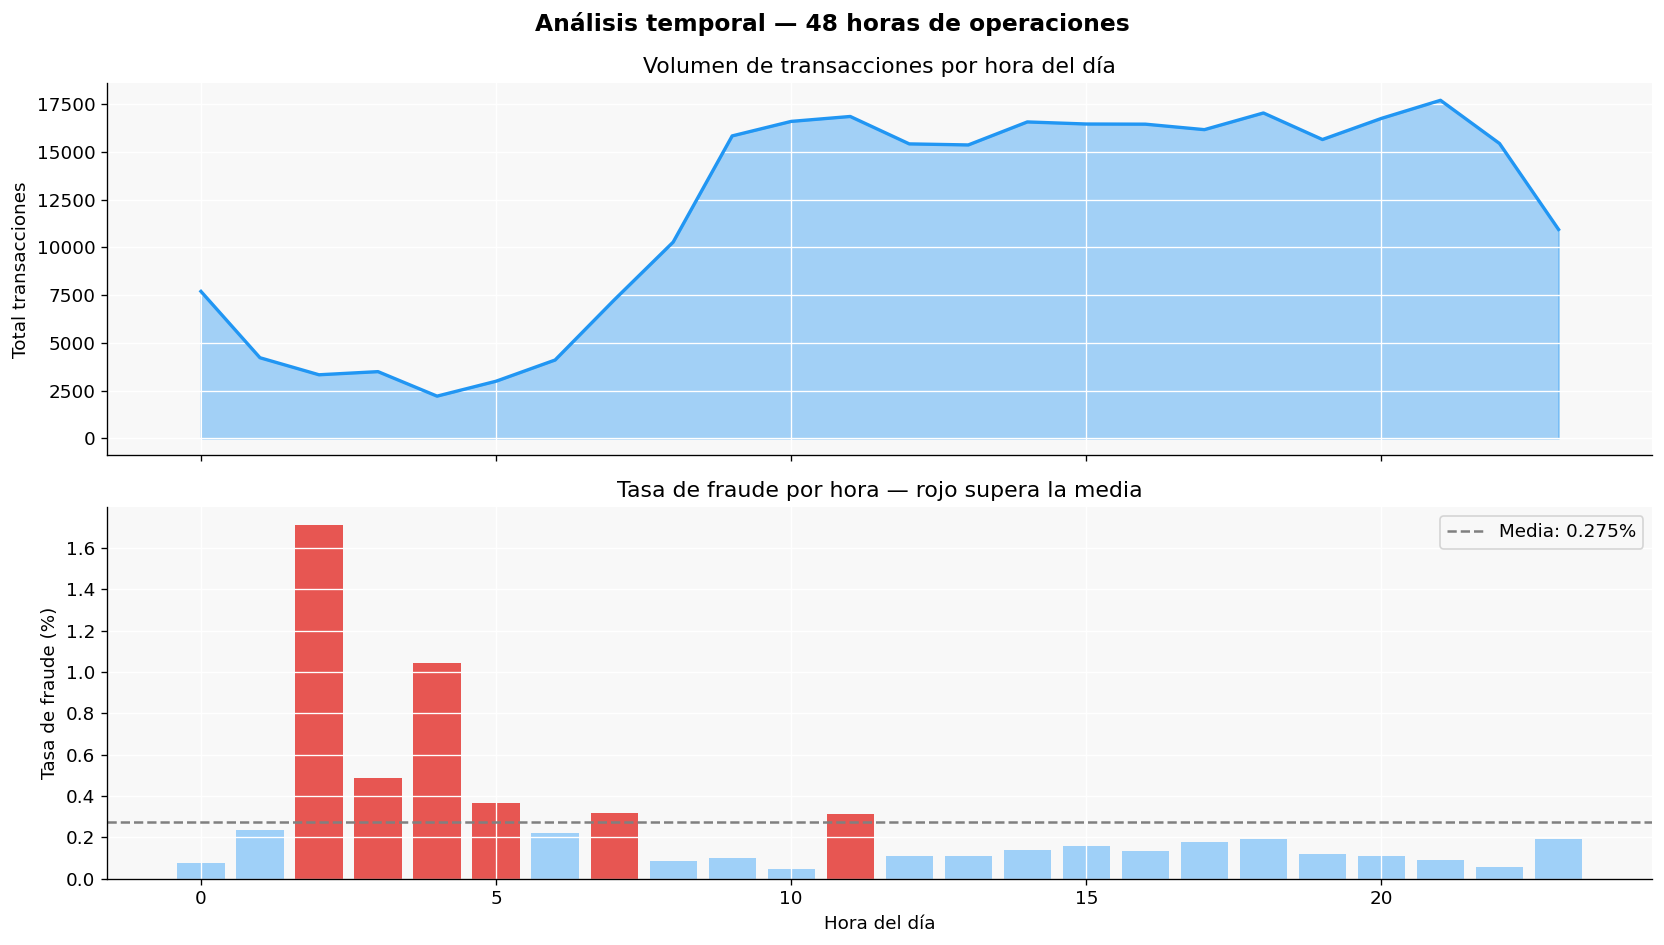

In [10]:
# Convertir segundos a horas
df["hora"] = (df["Time"] / 3600) % 24

hora_stats = df.groupby(df["hora"].astype(int))["Class"].agg(
    total="count",
    fraudes="sum"
).assign(tasa_fraude=lambda x: x["fraudes"] / x["total"] * 100)

fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

# Volumen total
ax = axes[0]
ax.fill_between(hora_stats.index, hora_stats["total"],
                alpha=0.4, color=C_LEGIT)
ax.plot(hora_stats.index, hora_stats["total"],
        color=C_LEGIT, linewidth=2)
ax.set_ylabel("Total transacciones")
ax.set_title("Volumen de transacciones por hora del día")

# Tasa de fraude
ax = axes[1]
ax.bar(hora_stats.index, hora_stats["tasa_fraude"],
       color=[C_FRAUD if t > hora_stats["tasa_fraude"].mean()
              else "#90CAF9" for t in hora_stats["tasa_fraude"]],
       alpha=0.85)
ax.axhline(hora_stats["tasa_fraude"].mean(),
           color="gray", linestyle="--", linewidth=1.5,
           label=f"Media: {hora_stats['tasa_fraude'].mean():.3f}%")
ax.set_ylabel("Tasa de fraude (%)")
ax.set_xlabel("Hora del día")
ax.set_title("Tasa de fraude por hora — rojo supera la media")
ax.legend()

plt.suptitle("Análisis temporal — 48 horas de operaciones",
             fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig(FIG_DIR / "02_analisis_temporal.png", bbox_inches="tight")
plt.show()

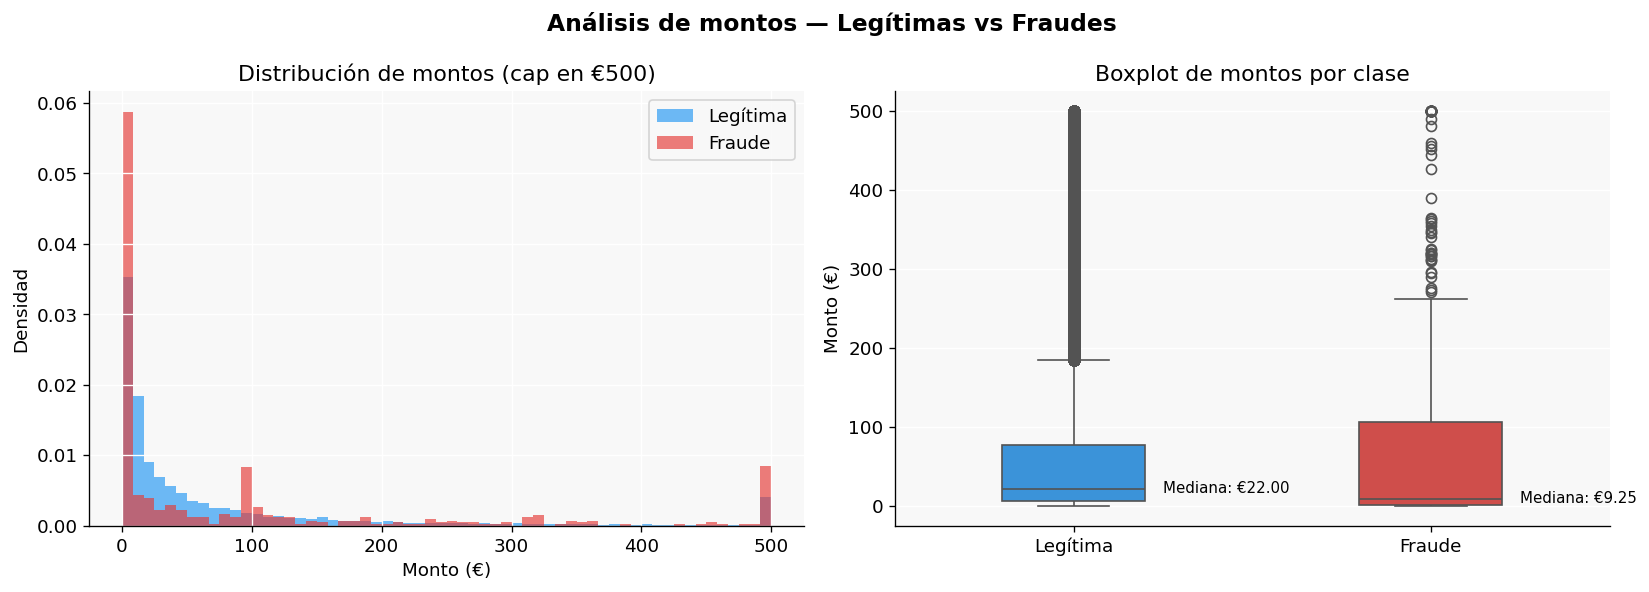

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histograma log-escala
ax = axes[0]
ax.hist(df[df["Class"]==0]["Amount"].clip(upper=500),
        bins=60, alpha=0.65, color=C_LEGIT,
        label="Legítima", density=True)
ax.hist(df[df["Class"]==1]["Amount"].clip(upper=500),
        bins=60, alpha=0.65, color=C_FRAUD,
        label="Fraude", density=True)
ax.set_xlabel("Monto (€)")
ax.set_ylabel("Densidad")
ax.set_title("Distribución de montos (cap en €500)")
ax.legend()

# Boxplot
ax = axes[1]
data_box = pd.DataFrame({
    "Monto": df["Amount"].clip(upper=500),
    "Clase": df["Class"].map({0: "Legítima", 1: "Fraude"})
})
sns.boxplot(data=data_box, x="Clase", y="Monto",
            palette=[C_LEGIT, C_FRAUD],
            order=["Legítima", "Fraude"],
            width=0.4, ax=ax)
ax.set_title("Boxplot de montos por clase")
ax.set_xlabel("")
ax.set_ylabel("Monto (€)")

# Medianas
for i, clase in enumerate(["Legítima", "Fraude"]):
    target = 0 if clase == "Legítima" else 1
    med = df[df["Class"]==target]["Amount"].median()
    ax.annotate(f"Mediana: €{med:.2f}",
                xy=(i, med), xytext=(i+0.25, med),
                fontsize=9, va="center")

plt.suptitle("Análisis de montos — Legítimas vs Fraudes",
             fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig(FIG_DIR / "03_analisis_montos.png", bbox_inches="tight")
plt.show()

In [12]:
stats = df.groupby("Class")[["Amount", "hora"]].agg(
    ["mean", "median", "std", "min", "max"]
).round(2)

stats.index = ["Legítima", "Fraude"]
print("Estadísticas por clase:")
print(stats.to_string())

Estadísticas por clase:
          Amount                                 hora                          
            mean median     std  min       max   mean median   std   min    max
Legítima   88.29  22.00  250.11  0.0  25691.16  14.54  15.01  5.84  0.00  24.00
Fraude    122.21   9.25  256.68  0.0   2125.87  12.14  12.05  6.72  0.11  23.99


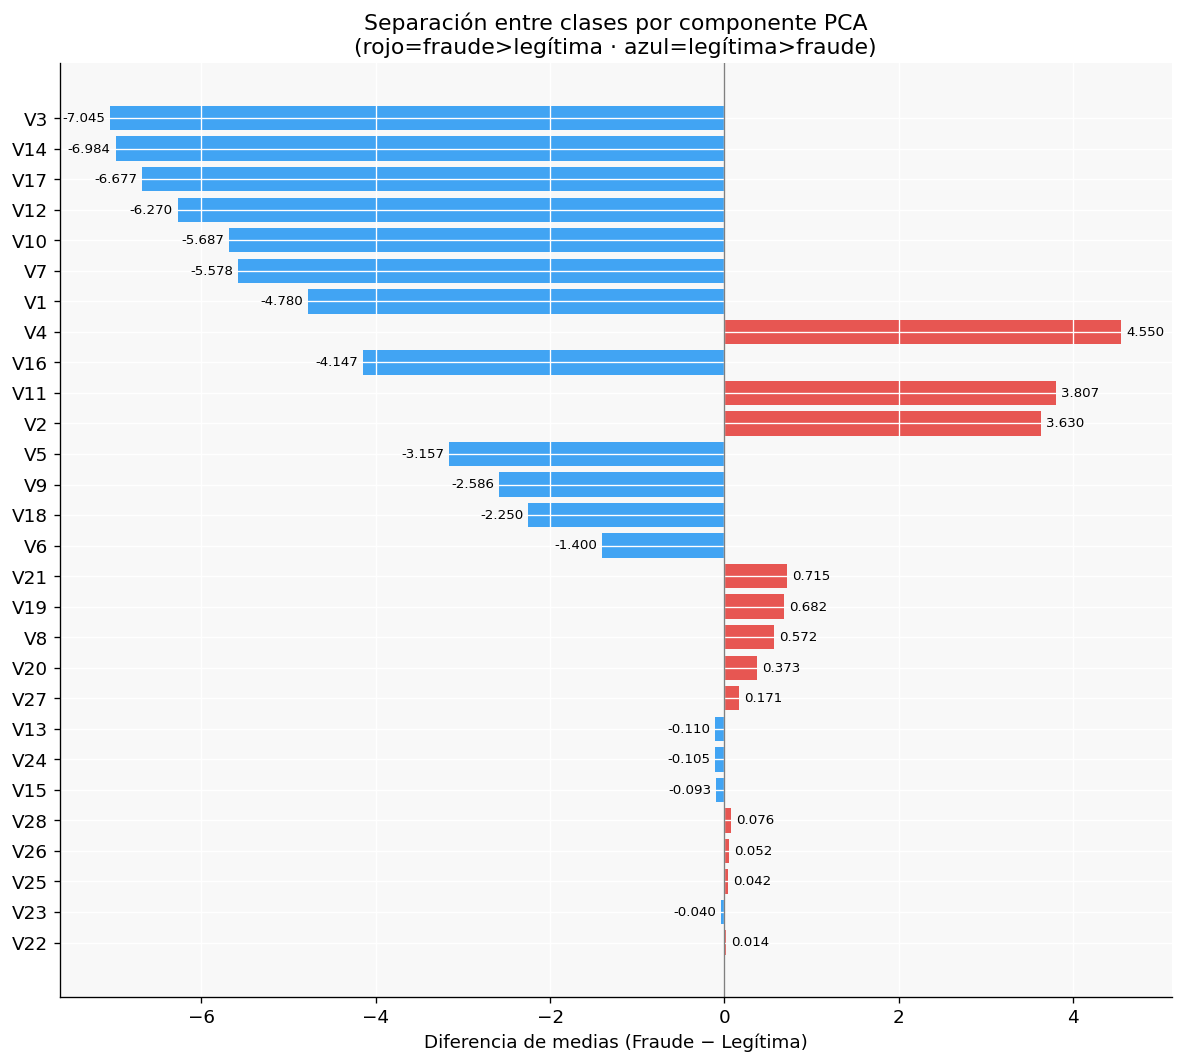

In [13]:
v_cols = [f"V{i}" for i in range(1, 29)]

diff_medias = (
    df[df["Class"]==1][v_cols].mean() -
    df[df["Class"]==0][v_cols].mean()
).sort_values(key=abs, ascending=True)

fig, ax = plt.subplots(figsize=(10, 9))
colors = [C_FRAUD if v > 0 else C_LEGIT for v in diff_medias]
bars = ax.barh(diff_medias.index, diff_medias.values,
               color=colors, alpha=0.85)
ax.bar_label(bars, fmt="%.3f", padding=3, fontsize=8)
ax.axvline(0, color="gray", linewidth=0.8)
ax.set_xlabel("Diferencia de medias (Fraude − Legítima)")
ax.set_title("Separación entre clases por componente PCA\n"
             "(rojo=fraude>legítima · azul=legítima>fraude)")
plt.tight_layout()
plt.savefig(FIG_DIR / "04_pca_separacion.png", bbox_inches="tight")
plt.show()

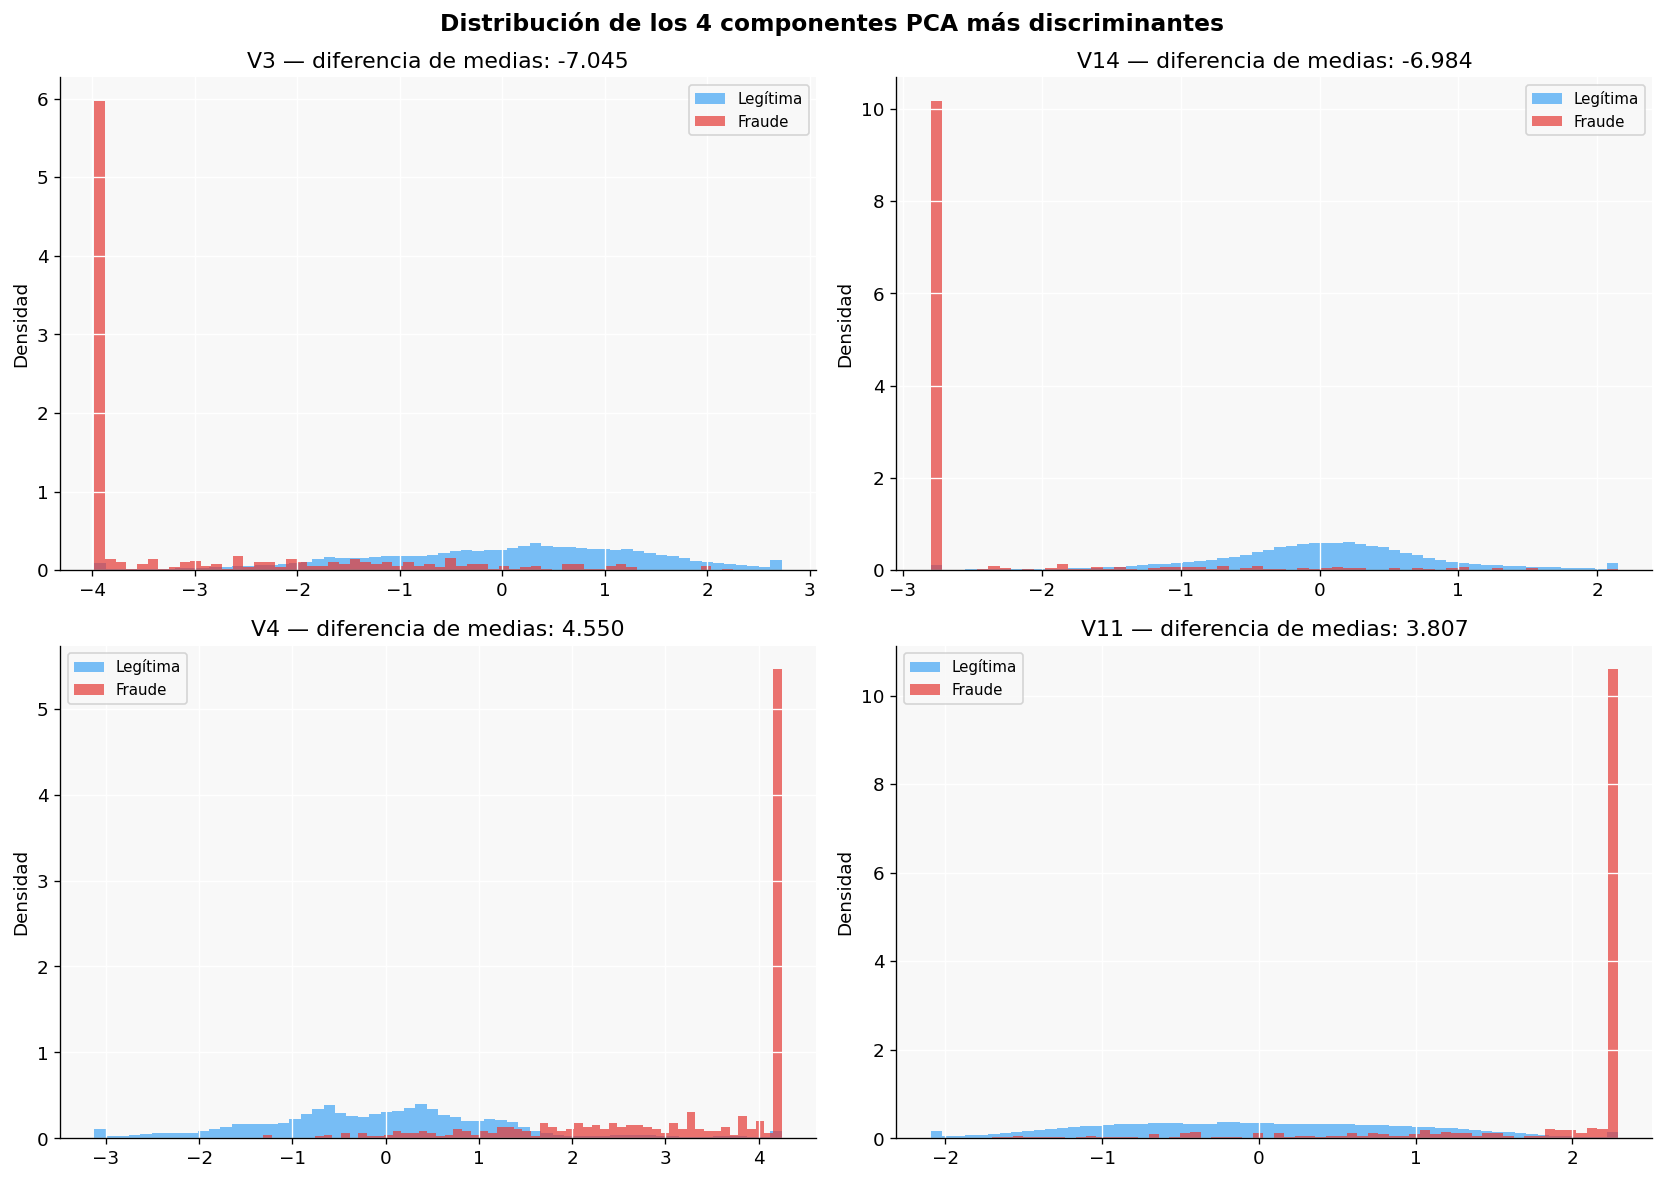

In [14]:
top_4 = ["V3", "V14", "V4", "V11"]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.ravel()

for i, col in enumerate(top_4):
    ax = axes[i]
    lo = df[col].quantile(0.01)
    hi = df[col].quantile(0.99)

    ax.hist(df[df["Class"]==0][col].clip(lo, hi),
            bins=60, alpha=0.6, color=C_LEGIT,
            density=True, label="Legítima")
    ax.hist(df[df["Class"]==1][col].clip(lo, hi),
            bins=60, alpha=0.7, color=C_FRAUD,
            density=True, label="Fraude")
    ax.set_title(f"{col} — diferencia de medias: "
                 f"{diff_medias[col]:.3f}")
    ax.set_ylabel("Densidad")
    ax.legend(fontsize=9)

plt.suptitle("Distribución de los 4 componentes PCA más discriminantes",
             fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig(FIG_DIR / "05_pca_top4.png", bbox_inches="tight")
plt.show()

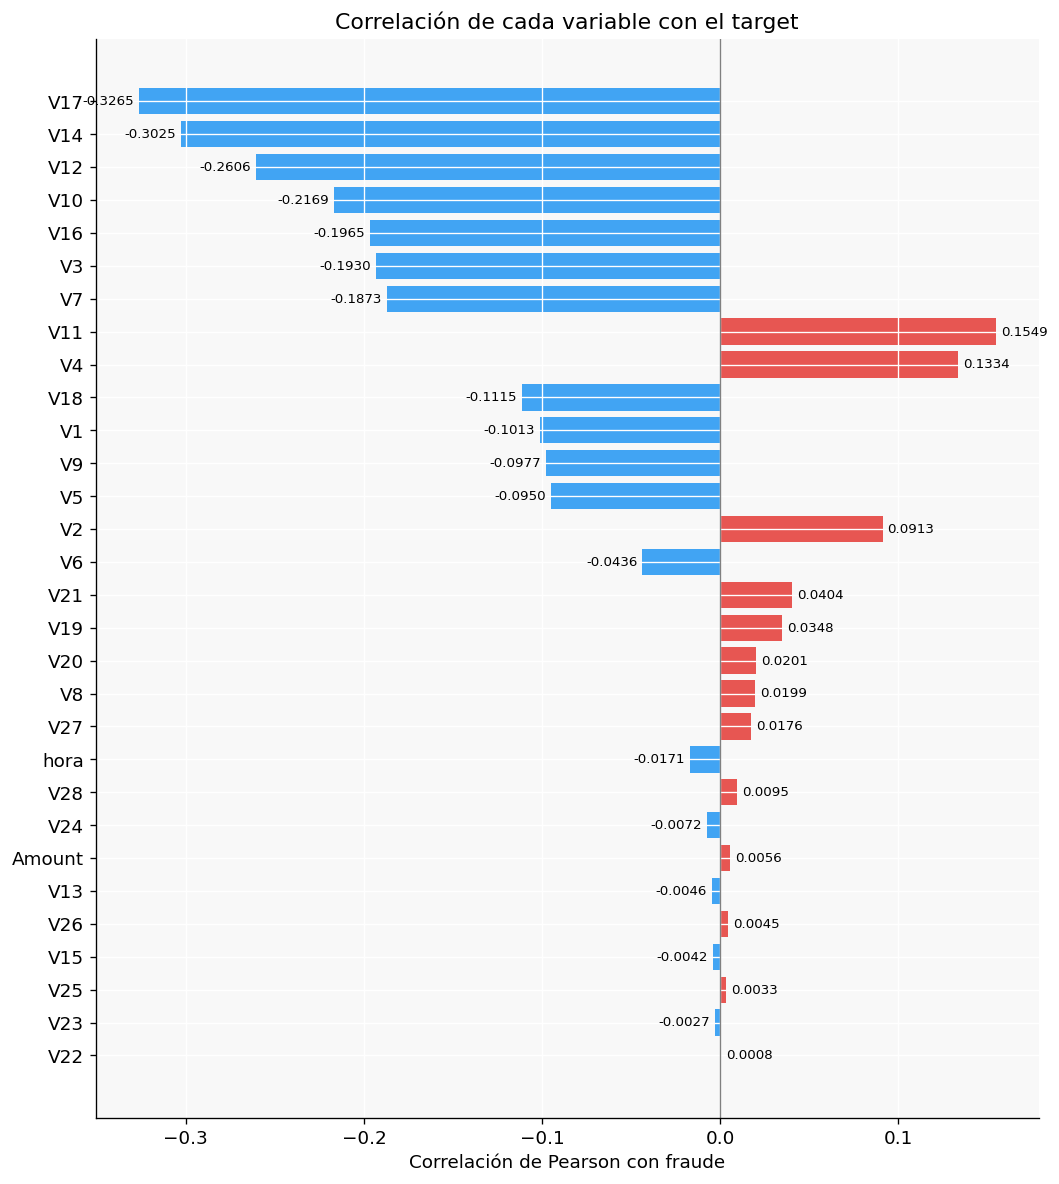

In [15]:
corr_target = df[v_cols + ["Amount", "hora"]].corrwith(
    df["Class"]
).sort_values(key=abs, ascending=False)

fig, ax = plt.subplots(figsize=(9, 10))
colors = [C_FRAUD if v > 0 else C_LEGIT for v in corr_target]
bars = ax.barh(corr_target.index[::-1],
               corr_target.values[::-1],
               color=colors[::-1], alpha=0.85)
ax.bar_label(bars, fmt="%.4f", padding=3, fontsize=8)
ax.axvline(0, color="gray", linewidth=0.8)
ax.set_xlabel("Correlación de Pearson con fraude")
ax.set_title("Correlación de cada variable con el target")
plt.tight_layout()
plt.savefig(FIG_DIR / "06_correlacion_target.png", bbox_inches="tight")
plt.show()

In [16]:
# Añadir variable log_amount para el modelo
df["log_amount"] = np.log1p(df["Amount"])

# Guardar
df.to_csv(DATA_PROCESSED / "fraud_clean.csv", index=False)
print(f"Dataset guardado ✓ {df.shape}")

# Resumen ejecutivo
print("\n" + "="*55)
print("RESUMEN EJECUTIVO — Fraud Detection EDA")
print("="*55)
print(f"\nTotal transacciones  : {len(df):,}")
print(f"Total fraudes        : {df['Class'].sum():,}")
print(f"Tasa de fraude       : {df['Class'].mean():.4%}")
print(f"Ratio desbalanceo    : 1:{int((df['Class']==0).sum()/df['Class'].sum())}")
print(f"\nMonto mediano legítima : €{df[df['Class']==0]['Amount'].median():.2f}")
print(f"Monto mediano fraude   : €{df[df['Class']==1]['Amount'].median():.2f}")
print(f"\nHora media legítima  : {df[df['Class']==0]['hora'].mean():.1f}h")
print(f"Hora media fraude    : {df[df['Class']==1]['hora'].mean():.1f}h")
print(f"\nComponentes más discriminantes:")
print(f"  Negativos: V17(-0.33), V14(-0.30), V12(-0.26)")
print(f"  Positivos: V11(+0.15), V4(+0.13), V2(+0.09)")
print(f"\nHallazgos clave:")
print(f"  · Fraudes de madrugada (2-5h) : tasa hasta 1.67%")
print(f"  · Fraudes de monto pequeño    : mediana €9.25")
print(f"  · Componentes V3,V14,V17,V4   : mayor separación")
print("="*55)

Dataset guardado ✓ (284807, 33)

RESUMEN EJECUTIVO — Fraud Detection EDA

Total transacciones  : 284,807
Total fraudes        : 492
Tasa de fraude       : 0.1727%
Ratio desbalanceo    : 1:577

Monto mediano legítima : €22.00
Monto mediano fraude   : €9.25

Hora media legítima  : 14.5h
Hora media fraude    : 12.1h

Componentes más discriminantes:
  Negativos: V17(-0.33), V14(-0.30), V12(-0.26)
  Positivos: V11(+0.15), V4(+0.13), V2(+0.09)

Hallazgos clave:
  · Fraudes de madrugada (2-5h) : tasa hasta 1.67%
  · Fraudes de monto pequeño    : mediana €9.25
  · Componentes V3,V14,V17,V4   : mayor separación
